# Limitation 3 — One line, two lines, three

**A window that resolves the companion fixes it on a line of the sky. One line is not a position; two lines cross somewhere, and the crossing is as good as the angle between them; three are the first set that can disagree. The atoms that pool lines and the atom that fits all windows both need lines from well spread directions, and neither refuses to answer when it has too few.**

Every limitation notebook has the same four parts. **The premise** states
what the atoms assume and shows the case that breaks it. Then **one section
per atom**, always in the same order, the two images of the windows, the map
of detections, the joint fit, each answering three questions: what does this
atom assume here, what does it return in this case, and does it warn you.
**The summary table** closes with the same columns every time: atom, effect,
alarm, remedy.

The case of this page: the control pair, 200 mas at position angle 110°, seen in one window, in two, in three, and then in many windows whose scans all lie in one narrow band of directions; and the pair at 60 mas on the Gaia forecast, which is resolved only by one bundle.

| block | task | calls | paper |
|---|---|---|---|
| setup | the toy instrument, the helpers, the detections of the control pair | `ins.Instrument.gaussian`, `ins.render_window`, `sim.simulate_window`, `joint.scene_positions_al` | Sect. 2.1, Eqs. 3–4 |
| 1 | the premise: a detection is a line on the sky; one, two, three lines, and one bundle | (the helpers) | Sect. 3.1, Eq. 10; Sect. 5.1 |
| 2 | the two images from a narrow band of directions | `radon.filtered_backprojection`, `radon.faststack` | App. C.2, Eq. C.3, Fig. C.1 |
| 3 | the map of one, two and three detections, and of one bundle | `bp.map_peak`, `bp.peak_consistency` | Sect. 3.3, Eq. 13; Sect. 5.1 |
| 4 | the joint fit's covariance in a band of directions | `joint.joint_fisher`, `joint.joint_covariance` | Sect. 4.3, Eq. 18; App. B.2, Eq. B.9 |

Every scanlib call carries the name of its module (`joint.fit_joint`); the first code cell lists the modules.

**The series.** The three images and the fit are in [`../00_three_images_and_fit.ipynb`](../00_three_images_and_fit.ipynb). The limitations: [1 — the finite window](01_finite_window.ipynb), [2 — the scan law](02_scan_law.ipynb), this page, [4 — a scene that moves](04_motion.ipynb), [5 — the blend](05_blend.ipynb), [6 — errors of the model, and the noise](06_model_errors.ipynb).

**Symbols and units** are defined once for the package and every notebook in [`docs/conventions.md`](../../../docs/conventions.md). This page uses ψ, (Δα\*, Δδ), η, σ_η and the detections, the map and its width, θ, the Fisher ellipse, and the laws.

In [1]:
# the imports: numpy, matplotlib, and the scanlib modules; every scanlib call below carries its module's name
import numpy as np
import matplotlib.pyplot as plt

from scanlib import instrument as ins      # the instrument: sampling, LSF, the along-scan projection (Eq. 9)
from scanlib import simulation as sim      # synthetic scenes and their windows
from scanlib import backprojection as bp   # the triangulation map and its peak
from scanlib import radon                  # the inverse Radon transform and faststack
from scanlib import joint                  # the joint fit of all windows, and its helpers

In [2]:
# the paper's figure style: font 10, ticks 9 and inward, thin axes; grays first, one accent
plt.rcParams.update({"font.size": 10.0, "axes.linewidth": 0.5, "xtick.labelsize": 9.0, "ytick.labelsize": 9.0,
                     "xtick.direction": "in", "ytick.direction": "in", "legend.frameon": False, "legend.fontsize": 7.5})
ACCENT = "tomato"                                          # the one accent
# the markers: each name below in capitals with dict(...) is a table of the keywords that ax.scatter takes for
# one kind of point
TRUTH = dict(marker="*", s=150, facecolor="white", edgecolor="k", lw=0.8, zorder=7)   # the truth
SEED = dict(marker="o", s=60, facecolor="none", edgecolor=ACCENT, lw=1.1, zorder=6)  # a starting point (the map's peak)
PRIMARY = dict(marker="+", s=110, color="k", lw=1.4, zorder=6)                       # the primary
# the labels of the two sky axes
EAST = r"$\Delta\alpha^{*}$  [mas]   (East $\leftarrow$)"
NORTH = r"$\Delta\delta$  [mas]"


def letter(ax, label, text=""):
    """Write a panel's letter, bold, inside the panel's top-left corner, and a few words after it.

    Inputs
        ax      the panel (a matplotlib Axes)
        label   the panel's letter, for example "a"
        text    the words after the letter (default: none)
    Returns nothing: the letter and the words are drawn on ax, on a white box that dims what is under them."""
    white_box = dict(fc="white", ec="none", pad=1.0, alpha=0.8)
    ax.text(0.04, 0.96, rf"$\bf{{({label})}}$ " + text, transform=ax.transAxes, va="top", ha="left", fontsize=9,
            bbox=white_box)

In [3]:
# the toy instrument, the noise, the pair's position angle and fluxes, the two sets of scan directions, and the
# sky grid of every image
FWHM = 100.0                                 # the LSF's full width at half maximum [mas]
# The instrument, defined once: 18 samples 59 mas apart, a Gaussian LSF of
# that FWHM, and the trial positions of the per-window reduction.
inst = ins.Instrument.gaussian(fwhm_mas=FWHM, pitch_mas=59.0, n_samples=18)
grid = inst.sample_grid_mas                  # sample centers along the scan [mas]
pitch = grid[1] - grid[0]                    # the distance between two neighboring samples: 59 mas
sigma_lsf = FWHM / (2.0 * np.sqrt(2.0 * np.log(2.0)))   # LSF sigma [mas], for the formulas
sigma_noise = 10.0                           # the noise sigma of one sample; the primary's total flux is 100 sigma
pa = np.deg2rad(110.0)                       # the pair's position angle [rad], counter-clockwise from north
flux = np.array([1000.0, 200.0])             # the fluxes of the primary and of the companion, in the windows' units
EVEN = np.linspace(0.0, np.pi, 80, endpoint=False) + 0.01     # 80 even directions [rad]
# ref: the reference cases of the package's tests, a table from a case's name to its array; two of its inputs
# are used here
ref = np.load("../../../tests/reference/reference_cases.npz")
GAIA = ref["static_pair/inputs/psi"]                           # the Gaia forecast's 40 scan angles [rad]
GAIA_TAU = ref["moving_pair/inputs/tau"]                       # and epochs [yr]
half = 400.0                                 # the sky grid of every image: half the side of the square [mas]
step = 4.0                                   # and the size of one pixel [mas]
# degrees of freedom of a static two-source fit on 80 windows: 80 x 18 samples, minus the companion's two
# coordinates and the two fluxes
DOF = EVEN.size * grid.size - 4

In [4]:
# helper: the companion's sky offset at a separation on the pair axis
def pair(rho):
    """The companion's sky offset at a separation on the pair axis (the direction of position angle pa).

    Inputs
        rho   the companion's separation from the primary [mas]
    Returns
        the companion's (dra*, ddec) [mas] from the primary, an array of two numbers"""
    pair_axis = np.array([np.sin(pa), np.cos(pa)])            # the unit vector of the pair axis, (dra*, ddec)
    return rho * pair_axis

In [5]:
# helper: the windows of a scene, noise-free or noisy (ins.render_window, sim.simulate_window)
def windows_of(theta, psi, flux=flux, tau=None, rng=None, present=None, eta0=None, inst=inst):
    """The windows of a scene, one per scan: noise-free (a formula), or with one draw of noise each.

    Inputs
        theta     the companions' parameters, one flat array: (dra*, ddec) [mas] per companion for a static scene,
                  (dra*, ddec [mas], mu_alpha*, mu_delta [mas/yr]) per companion for a moving one. The primary is
                  at the origin and has no entry
        psi       the scan angle of each of the J windows [rad]
        flux      the flux of each of the K sources, in the windows' units, the primary first
        tau       the epoch of each window [yr] for a moving scene (None: a static scene)
        rng       the random generator of the noise, of sigma_noise per sample (None: noise-free windows)
        present   J rows of K booleans: which source is in which window (None: every source in every window)
        eta0      the zero point of each window [mas] (None: every zero point is 0)
        inst      the instrument that renders the windows (default: the page's instrument)
    Returns
        the windows, an array of J rows of N samples, flux per sample"""
    # step 1, the along-scan position of every source in every window [mas]: one row per window, one column per
    # source, the primary first. Each window's zero point is subtracted from its row; [:, None] turns the J zero
    # points into a column, so that row j gets eta0[j]
    eta = joint.scene_positions_al(theta, psi, tau)
    if eta0 is not None:
        eta = eta - np.asarray(eta0)[:, None]

    # step 2, one window per scan; j counts the windows
    windows = []
    for j, eta_j in enumerate(eta):
        # the fluxes in window j: present[j] holds one True or False per source, and a source that is not in
        # the window gets flux 0
        if present is None:
            flux_j = flux
        else:
            flux_j = flux * present[j]
        # the samples of window j: the noise-free model, or the model plus one draw of noise from rng
        if rng is None:
            window = ins.render_window(eta_j, flux_j, inst)
        else:
            window = sim.simulate_window(eta_j, flux_j, inst, rng, sigma_noise)
        windows.append(window)
    return np.array(windows)

In [6]:
# helper, a stand-in for the per-window reduction: the Fisher error of each companion's position in one window
def sigma_eta(eta, flux=flux, sigma_noise=sigma_noise):
    """The Fisher error of each companion's along-scan position in one window, with every flux free. It is a
    formula, not a fit: it stands in for the error that the per-window reduction would report.

    Inputs
        eta           the along-scan position of each of the K sources in the window [mas], the primary first
        flux          the flux of each of the K sources, in the windows' units, the primary first
        sigma_noise   the noise sigma of one sample, in the windows' units
    Returns
        the 1-sigma error of each companion's position [mas], K - 1 numbers (the primary's position is not a
        parameter); every one is infinite where the Fisher matrix is singular"""
    # step 1, the model of the window. columns[:, k] is the window of source k alone at flux 1, one number per
    # sample; derivatives[:, k] is the derivative of that column with respect to the position of source k [1/mas]
    columns = inst.design_columns(eta)
    derivatives = inst.design_jacobian(eta)

    # step 2, the derivative of the window with respect to every parameter, one column each: first the
    # companions' positions ([:, 1:] omits the primary's column and flux[1:] the primary's flux), then the K fluxes
    jacobian = np.column_stack([derivatives[:, 1:] * flux[1:], columns])

    # step 3, the Fisher matrix for Gaussian noise of known sigma. Where its condition number is above 1e12 it
    # cannot be inverted safely: the companions' positions are then not measured in this window
    fisher = jacobian.T @ jacobian / sigma_noise ** 2
    n_companions = eta.size - 1
    if np.linalg.cond(fisher) > 1e12:
        return np.full(n_companions, np.inf)

    # step 4, the errors: the square roots of the diagonal of the inverse. [:n_companions] keeps the positions'
    # entries and omits the fluxes'
    covariance = np.linalg.inv(fisher)
    return np.sqrt(np.diag(covariance)[:n_companions])

In [7]:
# helper, the stand-in's detections: the truth plus one draw of that error, where the error is below 30 mas
def detections(theta, psi, flux=flux, tau=None, sigma_max=30.0, rng=None, present=None):
    """The teaching detections of a scene, a stand-in for the per-window reduction: no window is simulated and no
    window is fitted. A detection is a companion's true along-scan position in a window plus one Gaussian draw of
    its Fisher error there (sigma_eta, at the page's noise sigma_noise).

    Inputs
        theta       the companions' parameters, one flat array, as in windows_of
        psi         the scan angle of each of the J windows [rad]
        flux        the flux of each of the K sources, in the windows' units, the primary first
        tau         the epoch of each window [yr] for a moving scene (None: a static scene)
        sigma_max   a companion gives a detection in a window only where its Fisher error is finite and at most
                    this [mas]
        rng         the random generator of the draws (None: a new generator of seed 8 at every call)
        present     J rows of K booleans: which source is in which window (None: every source in every window);
                    a companion gives no detection in a window that it is not in
    Returns three arrays, one entry per detection
        psi     the scan angle of the detection's window [rad]
        eta     the detected along-scan position [mas]: the truth plus the draw
        sigma   the 1-sigma error of that position [mas]"""
    # step 1, the generator of the detections' errors. The default is a new generator of seed 8 at every call,
    # so two calls for the same scene give the same draws (why 8: not stated)
    if rng is None:
        rng_detections = np.random.default_rng(8)
    else:
        rng_detections = rng

    # step 2, the true along-scan position of every source in every window [mas]: row j is window j, column 0
    # the primary
    eta_true = joint.scene_positions_al(theta, psi, tau)

    # step 3, one detection per window and companion that passes the two tests. j counts the windows; c counts
    # the sources of a window from 1, because source 0 is the primary and gives no detection
    detected_psi = []
    detected_eta = []
    detected_sigma = []
    for j, psi_j in enumerate(psi):
        eta_j = eta_true[j]
        sigma_j = sigma_eta(eta_j, flux)                       # the Fisher error of each companion in window j
        for c in range(1, eta_j.size):
            sigma = sigma_j[c - 1]                             # sigma_j has no entry for the primary
            if present is not None and not present[j, c]:
                continue
            if np.isfinite(sigma) and sigma <= sigma_max:
                error_draw = rng_detections.normal(0.0, sigma)
                detected_psi.append(psi_j)
                detected_eta.append(eta_j[c] + error_draw)
                detected_sigma.append(sigma)
    return np.array(detected_psi), np.array(detected_eta), np.array(detected_sigma)

In [8]:
# helper: the points of a covariance ellipse
def ellipse(cov, center, n_sigma=1.0):
    """The outline of a covariance ellipse on the sky, as points to plot.

    Inputs
        cov       the 2 x 2 covariance of a position (dra*, ddec) [mas^2]
        center    the center of the ellipse, (dra*, ddec) [mas]
        n_sigma   the size of the ellipse, its Mahalanobis radius (1: the 1-sigma ellipse)
    Returns
        200 points around the ellipse, one row (dra*, ddec) [mas] per point; the last point repeats the first"""
    # step 1, the ellipse's axes: the eigenvalues are the variances along them [mas^2], the columns of
    # eigenvectors are their directions
    eigenvalues, eigenvectors = np.linalg.eigh(cov)

    # step 2, the unit circle at 200 angles around the full turn: row 0 holds the cosines, row 1 the sines
    angles = np.linspace(0, 2 * np.pi, 200)
    unit_circle = np.vstack([np.cos(angles), np.sin(angles)])

    # step 3, the circle stretched to the ellipse's semi-axes ([:, None] makes them a column: one factor per
    # row of the circle), turned to the axes' directions, and moved to the center. .T gives one row per point
    semi_axes = n_sigma * np.sqrt(eigenvalues)[:, None]
    stretched = semi_axes * unit_circle
    turned = eigenvectors @ stretched
    return turned.T + center

In [9]:
# helper: draw one sky image or map, east to the left, with the sources marked
def show(ax, image, axis, title, marks=None, **imshow_options):
    """Draw one sky image or map, east to the left, with the sources marked by plus signs.

    Inputs
        ax               the panel (a matplotlib Axes)
        image            the image or the map, M rows of M pixels: the rows are ddec, the columns dra*
        axis             the sky coordinate of the M rows, and of the M columns [mas]
        title            the panel's title
        marks            the sources to mark, one row (dra*, ddec) [mas] each (None: the primary at the origin and
                         the companion of this page, the global theta)
        imshow_options   keywords for ax.imshow, for example vmax, the value drawn black
    Returns
        the drawn image (matplotlib's AxesImage)"""
    # step 1, the defaults of the picture, used where the call names no other: white at 0 and black at the
    # highest value, and every pixel drawn as it is (no smoothing)
    imshow_options.setdefault("cmap", "gray_r")
    imshow_options.setdefault("vmin", 0.0)
    imshow_options.setdefault("interpolation", "nearest")

    # step 2, the picture: row 0 at the bottom (north up); axis[0] and axis[-1] are the first and the last
    # coordinate, given as the picture's left and right, and bottom and top
    extent = (axis[0], axis[-1], axis[0], axis[-1])
    drawn_image = ax.imshow(image, origin="lower", extent=extent, **imshow_options)

    # step 3, the plus signs: column 0 of the marks is dra*, column 1 is ddec
    if marks is None:
        marked_sources = np.vstack([[0.0, 0.0], theta])
    else:
        marked_sources = marks
    ax.scatter(marked_sources[:, 0], marked_sources[:, 1], marker="+", s=70, color=ACCENT, lw=1.1, zorder=6)

    # step 4, the title, the label, and the direction of the horizontal axis
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(EAST)
    ax.set_aspect("equal")
    ax.set_xlim(axis[-1], axis[0])                               # east to the left
    return drawn_image

In [10]:
# helper: one printed line that compares a fit with the truth
def report(name, fit, truth, dof):
    """Print one line that compares a joint fit with the truth.

    Inputs
        name    the words that open the line
        fit     the result of joint.fit_joint, a table from a name to a value. Four entries are read:
                fit["theta"] the fitted parameters, fit["sigma_theta"] their Fisher 1-sigma errors, fit["flux"]
                the fitted fluxes (the primary first) and fit["chi2"]
        truth   the true parameters, in the order and the units of fit["theta"]
        dof     the degrees of freedom of the fit
    Returns nothing. The printed line holds: fit - truth for every parameter; the pulls (fit - truth over the
    Fisher sigma); the fluxes of the first two sources; chi2 / dof."""
    difference = fit["theta"] - np.asarray(truth)
    pulls = difference / fit["sigma_theta"]
    # the numbers as text, joined by commas (a short comprehension: one piece of text per parameter)
    difference_text = ", ".join(f"{value:6.2f}" for value in difference)
    pulls_text = ", ".join(f"{value:5.1f}" for value in pulls)
    primary_flux = fit["flux"][0]
    companion_flux = fit["flux"][1]
    chi2_per_dof = fit["chi2"] / dof
    print(f"{name:40s} fit − truth ({difference_text})   pulls ({pulls_text})"
          f"   fluxes {primary_flux:.0f}, {companion_flux:.0f}   chi2/dof {chi2_per_dof:.2f}")

In [11]:
# the page's case: the control pair and its detections on the 80 even directions (one noise draw);
# first_detection is the detection that section 1 starts from
theta = pair(200.0)                                           # the companion's (dra*, ddec) [mas]
# the teaching detections (the stand-in, not a reduction of windows): the scan angle [rad], the along-scan
# position [mas] and its 1-sigma error [mas] of each
det_psi, det_eta, det_sigma = detections(theta, EVEN)
first_detection = 10                                          # the index of the one detection of section 1
print(f"{det_psi.size} detections from {EVEN.size} windows; "
      f"sigma from {det_sigma.min():.1f} to {det_sigma.max():.1f} mas")

76 detections from 80 windows; sigma from 4.6 to 24.2 mas


In [12]:
# helper: draw each detection as its line on the sky, with the lines at +-3 sigma
def draw_lines(ax, psi, eta, sigma, colors=None):
    """Draw each detection as its line on the sky, with the two lines at 3 sigma on either side of it. A
    detection says that the companion is on the line dra* sin(psi) + ddec cos(psi) = eta.

    Inputs
        ax                the panel (a matplotlib Axes)
        psi, eta, sigma   the detections, D numbers each: the scan angle [rad], the along-scan position [mas]
                          and its 1-sigma error [mas]
        colors            one color per detection (None: every line black)
    Returns nothing: the lines are drawn on ax."""
    # k counts the detections
    for k, (psi_k, eta_k, sigma_k) in enumerate(zip(psi, eta, sigma)):
        if colors is None:
            color = "k"
        else:
            color = colors[k]
        # the two unit vectors (dra*, ddec) of the detection: along its line, and across it (the scan direction)
        along_line = np.array([np.cos(psi_k), -np.sin(psi_k)])
        across_line = np.array([np.sin(psi_k), np.cos(psi_k)])
        # three lines: the detection itself (the wider line), and the two at -3 and +3 sigma (thin). Each is
        # drawn between its two ends, 600 mas along the line to either side; one row (dra*, ddec) per end
        for n_sigma, line_width in ((0, 0.9), (-3, 0.3), (3, 0.3)):
            ends = (eta_k + n_sigma * sigma_k) * across_line + np.outer([-600, 600], along_line)
            ax.plot(ends[:, 0], ends[:, 1], color=color, lw=line_width)

In [13]:
# helper: the detection at a given angle from detection first_detection
def nearest(gap_deg):
    """The detection whose direction is closest to a given angle from the direction of the first detection
    (the page's first_detection), on the half-turn.

    Inputs
        gap_deg   the wanted angle from the first detection's direction [deg], from 0 to 180
    Returns
        the index of that detection in the page's det_psi, det_eta and det_sigma"""
    # the angle of every detection's direction from the first one's, folded into the half-turn [deg]
    angle_from_first = np.degrees(np.mod(det_psi - det_psi[first_detection], np.pi))
    return int(np.argmin(np.abs(angle_from_first - gap_deg)))

In [14]:
# helper: the crossing of two detection lines, and its covariance
def crossing(psi, eta, sigma):
    """The point where two detection lines cross, and its covariance. Detection i says
    dra* sin(psi_i) + ddec cos(psi_i) = eta_i: two detections are two linear equations in (dra*, ddec).

    Inputs
        psi, eta, sigma   the two detections, two numbers each: the scan angle [rad], the along-scan position
                          [mas] and its 1-sigma error [mas]
    Returns two things
        point        the (dra*, ddec) of the crossing [mas]
        covariance   its 2 x 2 covariance [mas^2], from the two errors taken as independent"""
    # the matrix of the two equations: row i is (sin psi_i, cos psi_i); its inverse solves them
    equations = np.column_stack([np.sin(psi), np.cos(psi)])
    inverse = np.linalg.inv(equations)
    point = inverse @ eta
    # the errors of the two eta propagated through the same inverse; np.diag puts the two variances on a diagonal
    covariance = inverse @ np.diag(sigma ** 2) @ inverse.T
    return point, covariance

## 1. The premise, and the case that breaks it

*Paper: Sect. 3.1, Eq. 10 (a detection is a line on the sky); Sect. 5.1 (a candidate needs three crossings in the map). The cases of one and two lines are not in the paper; they are here to show why three is the minimum.*

A window at scan angle ψ that measures the companion at η = η̂ ± σ says
only that the companion lies on the line Δα\* sin ψ + Δδ cos ψ = η̂, within
±σ across it, anywhere along it. A position needs lines from directions
that surround the source. The case is too few lines, or lines from one
direction: a source seen in one scan, a pair resolved in two windows, three
windows, or in many windows that all scanned along nearly the same
direction. The figure draws one, two and three detections as lines on the
sky, and the forecast's 21 lines for the pair at 60 mas, which span 57° of
the half-turn. The plus is the primary and the star is the companion's
true position; each detection is its line with the lines at ±3σ.

In [15]:
# the detections of the pair at 60 mas on the Gaia forecast, and the directions they span: 180 deg minus the
# largest gap between the sorted directions (np.r_ appends the first direction plus 180 deg, to close the
# half-turn). `picks` holds the indices of the one, two and three detections of the figure
theta_close = pair(60.0)
# the teaching detections of that pair (the stand-in, not a reduction of windows)
close_psi, close_eta, close_sigma = detections(theta_close, GAIA)
# the directions spanned [deg]: the directions folded into the half-turn and sorted, then the gaps between
# neighbors, the gap from the last round to the first included
directions = np.sort(np.mod(close_psi, np.pi))
directions_closed = np.r_[directions, directions[0] + np.pi]
largest_gap_deg = np.degrees(np.diff(directions_closed).max())
spanned = 180.0 - largest_gap_deg
# picks: three lists of indices into the page's detections. The second detection is the one nearest to 90 deg
# from the first; the three detections are the first and those nearest to 60 and to 120 deg from it
picks = ([first_detection],
         [first_detection, nearest(90.0)],
         [first_detection, nearest(60.0), nearest(120.0)])
print(f"the pair at 60 mas on the forecast: {close_psi.size} of {GAIA.size} windows resolve it, "
      f"spanning {spanned:.0f}° of the half-turn")

the pair at 60 mas on the forecast: 21 of 40 windows resolve it, spanning 57° of the half-turn


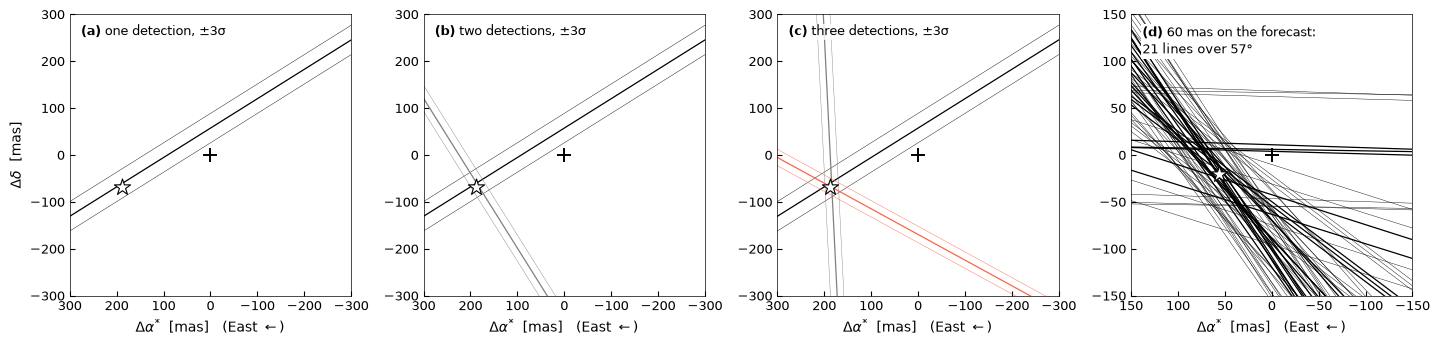

In [16]:
# the first figure. (a) to (c): one, two and three detections of the control pair as lines on the sky; (d): the
# forecast's lines for the pair at 60 mas. The plus is the primary, the star the companion's true position
fig, axes = plt.subplots(1, 4, figsize=(14.5, 4.0))
# step 1, (a) to (c): det_psi[pick] keeps the detections whose indices are in the list `pick`; the first line
# is black, the second gray, the third tomato
panel_names = ("one detection", "two detections", "three detections")
for ax, label, pick, name in zip(axes[:3], "abc", picks, panel_names):
    draw_lines(ax, det_psi[pick], det_eta[pick], det_sigma[pick], colors=["k", "0.5", ACCENT])
    ax.scatter(0, 0, **PRIMARY)
    ax.scatter(*theta, **TRUTH)                               # truth: the companion's true position
    letter(ax, label, f"{name}, ±3σ")
    ax.set(xlim=(300, -300), ylim=(-300, 300), aspect="equal", xlabel=EAST)       # east to the left

# step 2, (d): every detection of the pair at 60 mas on the forecast, on a smaller piece of sky
draw_lines(axes[3], close_psi, close_eta, close_sigma)
axes[3].scatter(0, 0, **PRIMARY)
axes[3].scatter(*theta_close, **TRUTH)                        # truth: the companion's true position
letter(axes[3], "d", f"60 mas on the forecast:\n{close_psi.size} lines over {spanned:.0f}°")
# axes[3].texts[-1] is the text that `letter` wrote last, the panel's letter
axes[3].texts[-1].set_bbox(dict(fc="white", ec="none", pad=1.0))   # the lines are dense in this corner: an opaque box
axes[3].set(xlim=(150, -150), ylim=(-150, 150), aspect="equal", xlabel=EAST)
axes[0].set_ylabel(NORTH)
plt.tight_layout()
plt.show()

## 2. The two images

*Paper: App. C.2, Eq. C.3 (the inverse Radon transform) and its text on faststack; Fig. C.1 (a gap in the directions). A band of 5° is not in the paper; it is here as the extreme of that gap.*

**What they assume.** The images do not use detections; they use every
window. Their premise is coverage of the half-turn (limitation notebook 2).

**What they return.** With windows from one narrow band of directions the
inverse Radon transform's image of a point is one streak along the band,
and faststack's stars are the polygons the band's strips cut out. The
figure shows both for the control pair scanned within a 5° band.

**Do they warn.** No.

In [17]:
# 20 noise-free windows within a 5 degree band about the pair axis, and the two images from them.
# radon.faststack returns four things; `_` drops the three that are not the image
band = pa + np.deg2rad(np.linspace(-2.5, 2.5, 20, endpoint=False))    # the 20 scan angles of the band [rad]
wins = windows_of(theta, band)
image, axis = radon.filtered_backprojection(band, wins, inst, half, step)
stack, _, _, _ = radon.faststack(band, wins, inst, half, step)

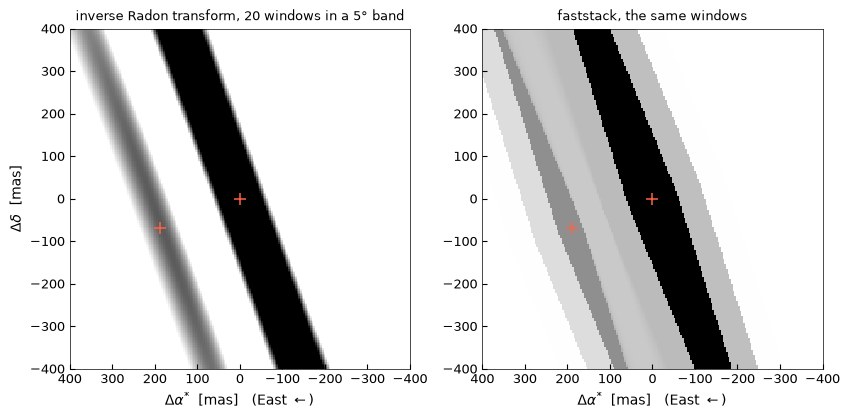

In [18]:
# the two images side by side, with the two sources marked
fig, axes = plt.subplots(1, 2, figsize=(8.6, 4.4))
show(axes[0], image, axis, "inverse Radon transform, 20 windows in a 5° band", vmax=0.02)
show(axes[1], stack, axis, "faststack, the same windows", vmax=250)
axes[0].set_ylabel(NORTH)
plt.tight_layout()
plt.show()

## 3. The map of detections

*Paper: Sect. 3.3, Eq. 13 (the map); Sect. 5.1 (the detections whose lines pass through a peak, and the minimum of three crossings). The covariance of a crossing of two lines is not in the paper; App. B.2 gives the information matrix of many.*

**What it assumes.** That the lines come from directions around the
source, so that their crossing is a point.

**What it returns.** One detection: the map is one ridge. `bp.map_peak` does
not refuse: every pixel on the crest is a local maximum, it returns the
first of them on the grid, and the width it reports is set by the
detection's σ and says nothing about the position along the line;
`bp.peak_consistency` passes the one line trivially. Two detections: a
crossing anywhere, whose error is set by the angle between the lines; with
A the 2 × 2 matrix of the normals the crossing's covariance is A⁻¹
diag(σᵢ²) A⁻ᵀ, with a long axis of about σ / sin(ψ₂ − ψ₁): at 90° the two
errors add in quadrature, at 5° the crossing slides tens of σ along the
lines, while `bp.map_peak` still reports the crest's width across, a few mas.
Three detections: the first set that can disagree, and the first for which
`bp.peak_consistency` has a job; a wrong third line makes a triangle, the peak
moves to the best pair of its corners, and the line that misses is the one
reported. Many lines in one bundle: the pair at 60 mas on the forecast, 21
lines over 57°, gives a peak ten times longer along than across.

**The figure** shows the six maps. The plus signs are the two sources and
the open circle is the peak that `bp.map_peak` returns. In the two panels of
three lines the detections are drawn over the map with their ±3σ lines;
the third line, the one that is shifted in the second of them, is the
tomato one.

**Does it warn.** The width `bp.map_peak` reports is the narrow one, so no.
`bp.peak_consistency` warns from three lines on; the line count and their
angular span are the reader's check before that.

In [19]:
# the map of one detection. det_psi[[first_detection]] is an array of one element, that detection. bp.map_peak
# returns the peak, its width, the map and the map's axis; bp.peak_consistency returns the mask of the lines that
# pass through the peak (and their distances, dropped here with `_`)
rows = []                                                     # not used below
one_psi = det_psi[[first_detection]]
one_eta = det_eta[[first_detection]]
one_sigma = det_sigma[[first_detection]]
peak, width, sky_one, axis_one = bp.map_peak(one_psi, one_eta, one_sigma, 300.0, 1.0)
keep, _ = bp.peak_consistency(one_psi, one_eta, one_sigma, peak, width)
# truth: the distance of the map's peak from the companion's true position [mas]
peak_error = np.array(peak) - theta
peak_distance = np.hypot(peak_error[0], peak_error[1])
print(f"one detection (sigma {det_sigma[first_detection]:.1f} mas): map_peak ({peak[0]:.0f}, {peak[1]:.0f}), "
      f"{peak_distance:.0f} mas from the truth, width {width:.1f} mas; peak_consistency keeps {keep.sum()} of 1")

one detection (sigma 8.9 mas): map_peak (-68, 100), 306 mas from the truth, width 6.0 mas; peak_consistency keeps 1 of 1


In [20]:
# the figure's panels are collected in `panels`, one entry per map: the map, its axis, its peak and its title.
# The first entry is the map of one detection
# panels: a list of tables, one per panel of the figure. A table holds "sky" the map, "axis" the map's axis
# [mas], "peak" the map's peak (dra*, ddec) [mas] and "title"; two panels add "lines" (the detections to draw
# as lines) and one adds "marks" (the sources to mark)
panels = []
title_one = f"one detection: a ridge\n'peak' {peak_distance:.0f} mas off, width {width:.1f}"
panels.append(dict(sky=sky_one, axis=axis_one, peak=peak, title=title_one))

In [21]:
# two detections, 90 and 5 degrees apart: the crossing of the two lines with its covariance (the helper
# `crossing`), the angle between them on the half-turn, and the map's peak
for gap_deg in (90.0, 5.0):
    # step 1, the two detections: the first, and the one nearest to gap_deg from it
    pick = [first_detection, nearest(gap_deg)]
    two_psi = det_psi[pick]
    two_eta = det_eta[pick]
    two_sigma = det_sigma[pick]

    # step 2, where the two lines cross, and the two axes of the crossing's error ellipse [mas], the shorter first
    point, cov = crossing(two_psi, two_eta, two_sigma)
    error_axes = np.sqrt(np.linalg.eigvalsh(cov))
    # truth: the distance of the crossing from the companion's true position [mas]
    crossing_distance = np.hypot(*(point - theta))            # * unpacks the difference (dra*, ddec)

    # step 3, the angle that the two detections really have between them [deg]. A direction is a line, so psi
    # and psi + 180 deg are the same: exp(2 i difference) has twice the difference as its phase, np.angle folds
    # it into -180 to 180 deg, and half of its absolute value is the angle between the two lines
    difference = det_psi[pick[1]] - det_psi[first_detection]
    actual = np.degrees(np.abs(np.angle(np.exp(2j * difference)))) / 2

    # step 4, the map of the two detections: its peak, its width, the map and the map's axis
    peak, width, sky_map, map_axis = bp.map_peak(two_psi, two_eta, two_sigma, 300.0, 1.0)
    print(f"two detections {actual:4.1f}° apart: crossing {crossing_distance:.0f} mas from the truth, "
          f"error axes {error_axes[0]:.1f} and {error_axes[1]:.1f} mas; map_peak width {width:.1f} mas")
    title = (f"two detections {actual:.0f}° apart\n"
             f"error axes {error_axes[0]:.0f} and {error_axes[1]:.0f} mas; bp.map_peak width {width:.1f}")
    panels.append(dict(sky=sky_map, axis=map_axis, peak=peak, title=title))

two detections 90.0° apart: crossing 9 mas from the truth, error axes 4.9 and 8.9 mas; map_peak width 2.3 mas
two detections  4.5° apart: crossing 12 mas from the truth, error axes 5.5 and 144.1 mas; map_peak width 5.3 mas


In [22]:
# three detections, consistent and with the third line moved by 60 mas (eta_three[2] is the third line's eta):
# the map's peak, and the lines that pass through it
pick_three = picks[2]                                         # the indices of the three detections
three_psi = det_psi[pick_three]
three_sigma = det_sigma[pick_three]
for shift, name in zip((0.0, 60.0), ("three consistent lines", "one of three lines 60 mas off")):
    # the three eta, a copy so that the page's detections do not change, with the third moved by `shift` [mas]
    eta_three = det_eta[pick_three].copy()
    eta_three[2] += shift
    peak, width, sky_map, map_axis = bp.map_peak(three_psi, eta_three, three_sigma, 300.0, 1.0)
    # keep: the mask of the lines that pass through the peak; distances: of the peak from each line [mas]
    keep, distances = bp.peak_consistency(three_psi, eta_three, three_sigma, peak, width)
    # truth: the distance of the map's peak from the companion's true position [mas]
    peak_error = np.array(peak) - theta
    peak_distance = np.hypot(peak_error[0], peak_error[1])
    print(f"{name}: peak {peak_distance:.0f} mas from the truth, width {width:.1f}; "
          f"lines through it {keep.sum()} of 3, distances {np.round(distances, 1)} mas")
    title = f"{name}\npeak {peak_distance:.0f} mas off, {keep.sum()} of 3 lines through it"
    panels.append(dict(sky=sky_map, axis=map_axis, peak=peak, lines=(three_psi, eta_three, three_sigma),
                       title=title))

three consistent lines: peak 3 mas from the truth, width 6.5; lines through it 3 of 3, distances [7.2 1.1 1. ] mas
one of three lines 60 mas off: peak 71 mas from the truth, width 2.5; lines through it 2 of 3, distances [70.8  0.3  0.2] mas


In [23]:
# one bundle: the forecast's lines for the pair at 60 mas; the half-widths of the region above half the peak
# (the boolean mask `region`), across and along
peak, width, sky_map, map_axis = bp.map_peak(close_psi, close_eta, close_sigma, 150.0, 1.0)
sky_x, sky_y = np.meshgrid(map_axis, map_axis)                # dra* and ddec of every pixel [mas]
region = sky_map >= 0.5 * sky_map.max()
# the 2 x 2 covariance of the region's pixel coordinates [mas^2] (row 0 dra*, row 1 ddec, measured from the
# peak); the square roots of its eigenvalues are the two half-widths [mas], the smaller first
coordinates = np.vstack([sky_x[region] - peak[0], sky_y[region] - peak[1]])
moments = np.cov(coordinates)
narrow, long_ = np.sqrt(np.linalg.eigvalsh(moments))
print(f"60 mas on the forecast, {close_psi.size} lines over {spanned:.0f}°: peak ({peak[0]:.0f}, {peak[1]:.0f}) "
      f"vs truth ({theta_close[0]:.0f}, {theta_close[1]:.0f}); half-widths {narrow:.0f} across, {long_:.0f} along")
marks_close = np.vstack([[0.0, 0.0], theta_close])            # the primary at the origin, and the companion
title = (f"60 mas on the forecast: {close_psi.size} lines over {spanned:.0f}°\n"
         f"half-widths {narrow:.0f} across, {long_:.0f} along")
panels.append(dict(sky=sky_map, axis=map_axis, peak=peak, marks=marks_close, title=title))

60 mas on the forecast, 21 lines over 57°: peak (67, -6) vs truth (56, -21); half-widths 7 across, 69 along


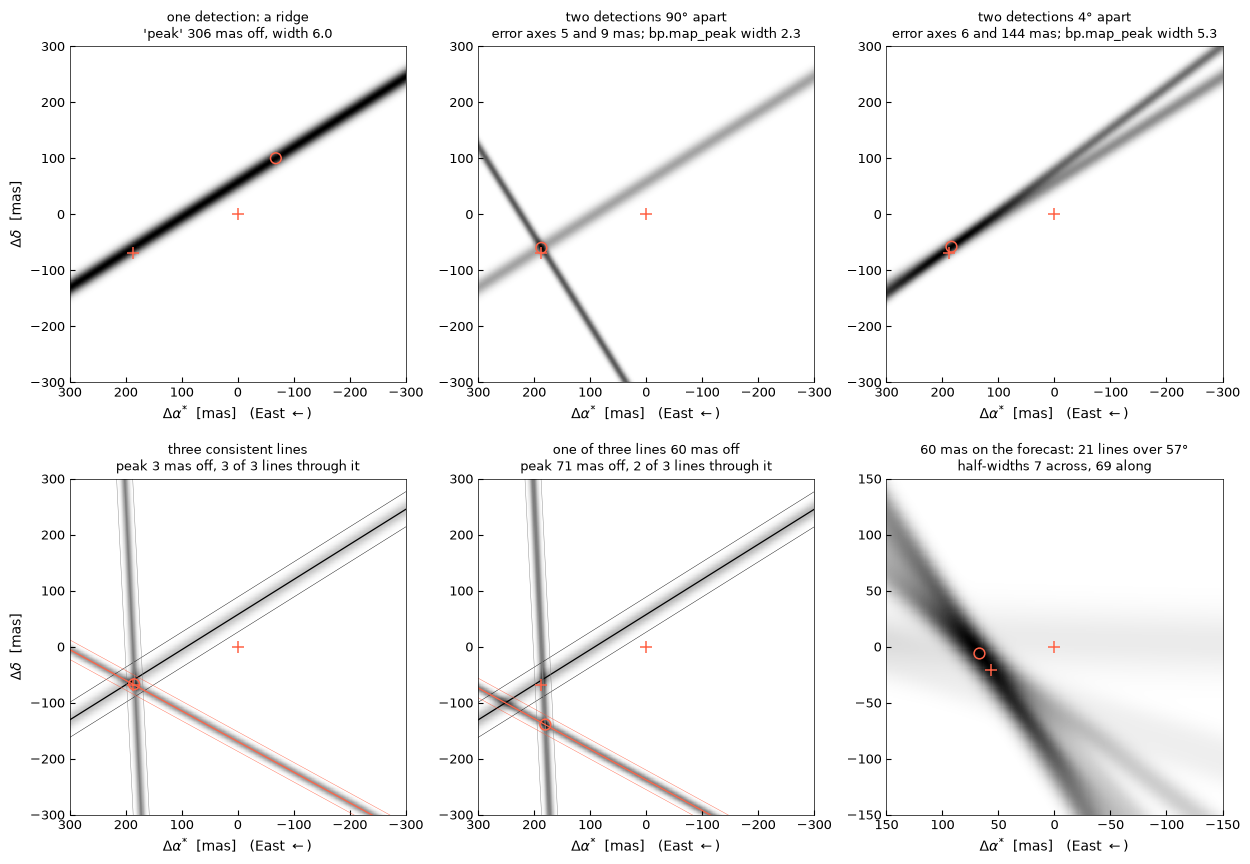

In [24]:
# the six maps, with the two sources (plus signs) and the map's peak (open circle); the two panels of three
# lines also get the lines themselves, the third in tomato
fig, axes = plt.subplots(2, 3, figsize=(12.6, 8.8))
# axes.flat runs over the six panels row by row
for ax, panel in zip(axes.flat, panels):
    # panel.get("marks") is the panel's "marks", or None where the panel has none: `show` then marks the
    # primary and the page's companion
    show(ax, panel["sky"], panel["axis"], panel["title"], panel.get("marks"))
    if "lines" in panel:
        # *panel["lines"] unpacks the three arrays (psi, eta, sigma) of the panel's detections
        draw_lines(ax, *panel["lines"], colors=["k", "0.5", ACCENT])
        ax.set(xlim=(300, -300), ylim=(-300, 300))
    ax.scatter(*panel["peak"], **SEED)
# axes[:, 0] is the first panel of each row
for ax in axes[:, 0]:
    ax.set_ylabel(NORTH)
plt.tight_layout()
plt.show()

## 4. The joint fit

*Paper: Sect. 4.3, Eq. 18 (the joint likelihood); App. B.2, Eq. B.9 (the position error for even coverage, which a band of directions does not have).*

**What it assumes.** Nothing about the directions; it returns the
covariance of whatever windows it is given.

**What it returns.** From 20 windows within a band of directions about the
pair axis, the Fisher ellipse of the companion's position grows along the
direction no scan measured as the band narrows: 1.5 mas on both axes over
the half-turn, 1.1 by 45 mas in a 5° band. The fit still converges and
returns a covariance; the long axis is the answer's honest statement that
one direction was never measured.

**Does it warn.** Yes, in the covariance, if it is read: the long axis is
the warning. χ² is silent, because nothing is wrong with the model.

**The figure** draws covariance ellipses at Mahalanobis radius 1 (the
legend's 1σ), which in two dimensions enclose 39.3 % of the probability,
not 68 % ([conventions](../../../docs/conventions.md)).

band about the pair axis, 20 windows -> Fisher sigma and ellipse axes of the companion's position [mas]
    180°: sigma (1.5, 1.5), axes 1.5 and 1.5
     90°: sigma (1.4, 2.4), axes 1.2 and 2.5
     45°: sigma (1.9, 4.5), axes 1.1 and 4.8
     20°: sigma (3.8, 10.5), axes 1.1 and 11.1
      5°: sigma (15.2, 41.9), axes 1.1 and 44.6


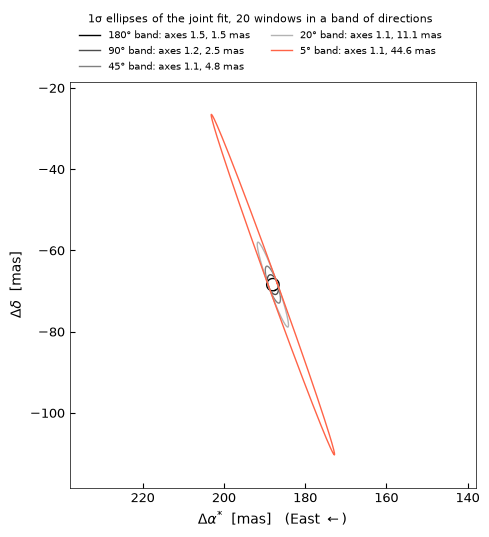

In [25]:
# The joint fit's 1-sigma ellipse from 20 windows in a band of directions of shrinking width, from the half-turn
# (black) to 5 degrees (tomato); all ellipses are centered on the companion's true position. cov[:2, :2] is
# the position's 2 x 2 block of the covariance
fig, ax = plt.subplots(figsize=(5.0, 5.6))
print("band about the pair axis, 20 windows -> Fisher sigma and ellipse axes of the companion's position [mas]")
for span_deg, color in zip((180.0, 90.0, 45.0, 20.0, 5.0), ("k", "0.3", "0.5", "0.7", ACCENT)):
    # the 20 scan angles of the band [rad], centered on the pair axis
    psi = pa + np.deg2rad(np.linspace(-span_deg / 2, span_deg / 2, 20, endpoint=False))
    # the Fisher covariance at the truth (a formula: no windows, no fit and no noise draw).
    # joint.joint_covariance(..., 2) returns the covariance of all the parameters and the 1-sigma of the first
    # two, the position; variances are those along the ellipse's two axes [mas^2], the smaller first
    fisher = joint.joint_fisher(theta, flux, psi, inst, sigma_noise)
    cov, sigma_position = joint.joint_covariance(fisher, 2)
    variances = np.linalg.eigvalsh(cov[:2, :2])
    short_axis = np.sqrt(variances[0])
    long_axis = np.sqrt(variances[1])
    outline = ellipse(cov[:2, :2], theta)
    ax.plot(outline[:, 0], outline[:, 1], color=color, lw=1,
            label=f"{span_deg:.0f}° band: axes {short_axis:.1f}, {long_axis:.1f} mas")
    print(f"  {span_deg:5.0f}°: sigma ({sigma_position[0]:.1f}, {sigma_position[1]:.1f}), "
          f"axes {short_axis:.1f} and {long_axis:.1f}")
ax.set(aspect="equal", xlabel=EAST, ylabel=NORTH)
ax.set_xlim(theta[0] + 50, theta[0] - 50)                         # east to the left
ax.set_ylim(theta[1] - 50, theta[1] + 50)
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=2, title_fontsize=8,
          title="1σ ellipses of the joint fit, 20 windows in a band of directions")
plt.tight_layout()
plt.show()

## Summary

| atom | effect in this case | alarm | remedy |
|---|---|---|---|
| inverse Radon transform | one streak along the band | none | coverage of the half-turn; limitation notebook 2 |
| faststack | polygons cut by the band's strips | none | the same |
| map of detections | one line: a ridge and a 'peak' anywhere on it; two: a crossing with error σ / sin Δψ along the lines; three: the first consistency check; one bundle: a peak ten times longer along than across | `bp.map_peak`'s width is the narrow one and does not warn; `bp.peak_consistency` warns from three lines on | report a one-line source as a line; require three lines over a wide span before reading a position |
| joint fit | converges and returns a covariance whatever the directions; axes 1.1 by 45 mas in a 5° band | the long axis of the ellipse, if read | the same requirement on the directions, checked before the fit |

## What this establishes

- One detection is a line. The map and `bp.map_peak` return a point on it with
  the ridge's width; the point is not a position, and a source seen in one
  scan should be reported as the line it is.
- Two detections cross somewhere, with an error of σ / sin(Δψ) along the
  lines; three are the first that can disagree, and the first for which
  `bp.peak_consistency` has a job.
- Many lines in one bundle are one line with a smaller σ. The joint fit
  returns a covariance whatever the directions; its long axis is the
  warning, and a close companion on a clumped law lives in this regime.